# 02 Baselines on the validation year

- What it does: checks the evaluation code, then scores three baselines on 2023: random order (B0), past failure rate (B1) and logistic regression (B2).
- Inputs: `data/processed/model_table.parquet`.
- Outputs: `preds/B0_random_val.csv`, `preds/B1_past_fail_rate_val.csv`, `preds/B2_logreg_val.csv`, `results/validation_baselines.csv`, `results/rule_sensitivity_val.csv`, `results/figures/gains_curve_val_baselines.png`.

The test years (2024 onward) are not used anywhere in this notebook.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import evaluate as E
from src import models as M

SEED = 42
np.random.seed(SEED)

## 1. Check the metrics

Capacity is fixed: ISD visits the riskiest 20% of inspections first.

- Hit rate (`precision_at_k`): the share of those visits that find a failure. This is the headline metric.
- `catch_at_k`: the share of all failures that those visits find.

The self-test confirms that a perfect score gives `catch_at_k = min(1, k / base rate)` and a random score gives about `k`.

In [2]:
E.self_test()

evaluate.py self-test passed: perfect score gives catch_at_k = min(1, k / base rate); random and constant scores give about k


## 2. Load the data

Train on 2016 to 2022, evaluate on 2023.

In [3]:
table = M.load_model_table("../data/processed/model_table.parquet")
train = table[table["split"] == "train"]
val = table[table["split"] == "val"]
y_val = val[M.TARGET].to_numpy()

train_base_rate = train[M.TARGET].mean()
print(f"train: {len(train):,} inspections, fail rate {train_base_rate:.1%}")
print(f"val:   {len(val):,} inspections, fail rate {y_val.mean():.1%}")
print(f"best possible catch_at_k on validation: {min(1, E.K / y_val.mean()):.1%}")

train: 35,872 inspections, fail rate 60.0%
val:   5,521 inspections, fail rate 55.8%
best possible catch_at_k on validation: 35.9%


## 3. Score the baselines

- B0, random order: we assume the routine schedule ignores risk, so this stands for today's process (an assumption that notebook 04 checks roughly). B0 gives every inspection the same score, and the metric code averages over every possible random order. Its hit rate is therefore exactly the fail rate.
- B1, past failure rate: a rule an inspector could apply by hand. A restaurant with no history gets the average past failure rate of the training rows, so it sits in the middle of the ranking. (The routine fail rate would be the wrong scale: `prior_fail_rate` also counts re-inspections, which mostly pass, so it averages 0.37, not 0.60.)
- B2, logistic regression on the history features: the predictive baseline.

In [4]:
logreg = M.fit_logreg(train)

val_scores = {
    "B0_random": M.score_random(val),
    "B1_past_fail_rate": M.score_past_fail_rate(val, fallback=M.past_fail_rate_fallback(train)),
    "B2_logreg": logreg.predict_proba(M.linear_matrix(val))[:, 1],
}
for name, score in val_scores.items():
    M.save_preds(val, score, f"../preds/{name}_val.csv")

In [5]:
# Confidence intervals resample whole restaurants, because inspections of one restaurant are not independent.
baselines = E.results_table(y_val, val_scores, groups=val["licenseno"])
baselines.to_csv("../results/validation_baselines.csv", index=False)
baselines.round(3)

,model,auc,catch_at_k,precision_at_k,n,auc_lo,auc_hi,catch_at_k_lo,catch_at_k_hi,precision_at_k_lo,precision_at_k_hi
0,B0_random,0.500,0.200,0.558,5521,0.500,0.500,0.200,0.200,0.543,0.572
1,B1_past_fail_rate,0.717,0.288,0.804,5521,0.702,0.730,0.279,0.297,0.777,0.829
2,B2_logreg,0.776,0.319,0.889,5521,0.762,0.789,0.310,0.328,0.867,0.910


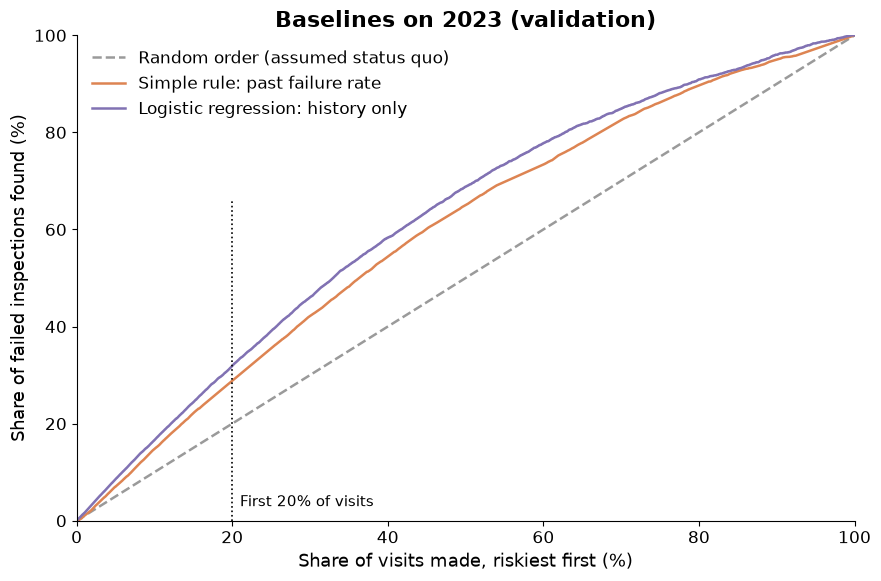

In [6]:
fig = E.plot_gains(y_val, val_scores, "Baselines on 2023 (validation)",
                   path="../results/figures/gains_curve_val_baselines.png")
plt.show()

## 4. Sensitivity: a second simple rule

How far a model beats "the rule" depends on which rule we pick. B1 is the rule we planned to benchmark against from the start. Another rule an inspector could apply by hand is "most violations at the last routine inspection first". It is shown here for honesty and is not one of the five models.

In [7]:
rule = E.results_table(y_val, {"B1_past_fail_rate": val_scores["B1_past_fail_rate"],
                               "S1_last_routine_violations": M.score_simple_rule(val)}, groups=val["licenseno"])
rule.to_csv("../results/rule_sensitivity_val.csv", index=False)
rule[["model", "auc", "catch_at_k", "precision_at_k", "precision_at_k_lo", "precision_at_k_hi"]].round(3)

,model,auc,catch_at_k,precision_at_k,precision_at_k_lo,precision_at_k_hi
0,B1_past_fail_rate,0.717,0.288,0.804,0.777,0.829
1,S1_last_routine_violations,0.724,0.303,0.844,0.823,0.867
